# Horas de internet e ingreso laboral

¿Existe una asociación entre las horas de uso de internet y el ingreso laboral de las personas ocupadas en Ecuador durante julio de 2025?

Se exploran dos variables: `pt3b` (horas) e `ingrl` (ingreso). Asociación no implica causalidad.

## Datos

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from data_loader import load_data

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05, rc={
    'figure.dpi': 110, 'figure.facecolor': '#FAFAF7', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
    'axes.titlepad': 12, 'grid.alpha': 0.18, 'figure.constrained_layout.use': True
})
verde, naranja = '#0F766E', '#D97706'

limpios = load_data('data_clean.parquet', revision='main')
aux = load_data('enemdu_persona_tics_2025_07.csv', revision='main')
aux = aux[['id_persona', 'periodo', 'p03', 'empleo', 'pt3a']].copy()
for col in ['id_persona', 'periodo', 'empleo', 'pt3a']:
    aux[col] = aux[col].astype('string').str.strip()

datos = limpios.merge(aux, on=['id_persona', 'periodo'], how='left', validate='one_to_one')
assert datos['p03'].notna().all(), 'Hay personas sin correspondencia en la base original'
assert datos['periodo'].eq('202507').all(), 'Revisar el periodo de la encuesta'

## Muestra
Se recuperan edad, empleo y frecuencia del CSV original. `empleo=1` delimita personas ocupadas de 15 años o más.

In [2]:
ocupados = datos.loc[datos['empleo'].eq('1') & datos['p03'].ge(15)].copy()
completos = ocupados.dropna(subset=['pt3b', 'ingrl']).copy()
muestra = completos.loc[completos['pt3a'].eq('1')].copy()

seleccion = pd.DataFrame({
    'Etapa': ['Base limpia', 'Ocupados de 15 años o más', 'Horas e ingreso disponibles', 'Uso diario y datos disponibles'],
    'Personas': [len(datos), len(ocupados), len(completos), len(muestra)]
})
seleccion['% de la base'] = (100 * seleccion['Personas'] / len(datos)).round(1)
display(seleccion.set_index('Etapa'))

,Personas,% de la base
Etapa,,
Base limpia,27509,100.0
Ocupados de 15 años o más,13299,48.3
Horas e ingreso disponibles,10091,36.7
Uso diario y datos disponibles,9881,35.9


### Disponibilidad
Conteos de personas ocupadas. Un ingreso no disponible no equivale a cero.

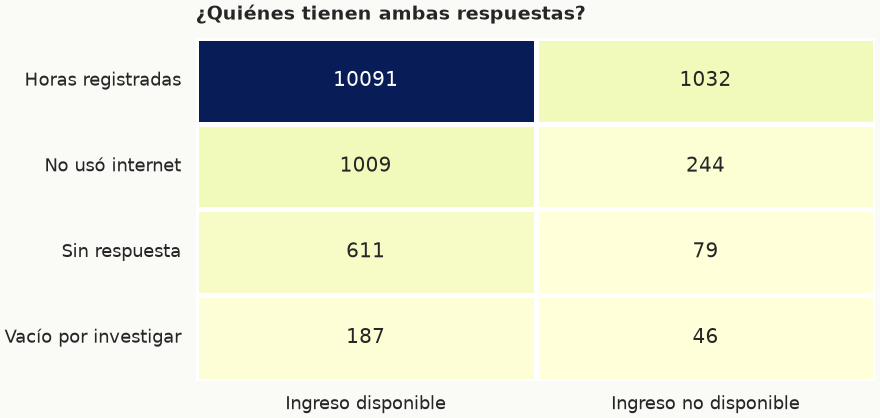

In [3]:
estado_horas = ocupados['internet_hours_status'].map({
    'Observed': 'Horas registradas', 'Nonresponse': 'Sin respuesta',
    'Not applicable': 'No usó internet', 'Potentially out of scope': 'Vacío por investigar'
})
estado_ingreso = ocupados['labor_income_status'].eq('Observed').map({
    True: 'Ingreso disponible', False: 'Ingreso no disponible'
})
cruce = pd.crosstab(estado_horas, estado_ingreso).reindex(
    ['Horas registradas', 'No usó internet', 'Sin respuesta', 'Vacío por investigar']
)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(cruce, annot=True, fmt='d', cmap='YlGnBu', linewidths=3,
            cbar=False, annot_kws={'size': 13}, ax=ax)
ax.set(title='¿Quiénes tienen ambas respuestas?', xlabel='', ylabel='')
ax.tick_params(axis='y', rotation=0)
plt.show()

### Referencia temporal
`pt3b` depende de `pt3a`. Se usa frecuencia diaria para no mezclar horas referidas a distintos periodos. El cero indica **menos de una hora**.
Julio es el mes de la encuesta; las preguntas de ingreso se refieren a junio. [Formulario INEC: 3A–3B e ingresos](https://www.ecuadorencifras.gob.ec/documentos/web-inec/Estadisticas_Sociales/TIC/2025/202507_Formulario_ENEMDU_Julio_2025.pdf).

In [4]:
frecuencias = completos['pt3a'].value_counts().reindex(['1', '2', '3', '4'], fill_value=0)
frecuencias.index = ['Diaria', 'Semanal', 'Mensual', 'Anual']
display(frecuencias.rename('Personas con ambas respuestas').to_frame())
print(f'Muestra diaria: {len(muestra):,} personas; {100 * len(muestra) / len(ocupados):.1f}% de los ocupados.')

,Personas con ambas respuestas
Diaria,9881
Semanal,194
Mensual,14
Anual,2


Muestra diaria: 9,881 personas; 74.3% de los ocupados.


## Distribuciones
Descriptivos sin ponderar. Se conservan los ceros y todos los ingresos observados.

In [5]:
resumen = muestra[['pt3b', 'ingrl']].rename(columns={
    'pt3b': 'Horas de internet', 'ingrl': 'Ingreso laboral (USD)'
}).describe(percentiles=[.25, .5, .75, .9, .99]).T
resumen = resumen.rename(columns={
    'count': 'n', 'mean': 'Media', 'std': 'Desviación', 'min': 'Mínimo', 'max': 'Máximo'
})
display(resumen.round(2))
print(f'Menos de una hora: {muestra.pt3b.eq(0).sum()} personas. Ingreso cero: {muestra.ingrl.eq(0).sum()} personas.')

,n,Media,Desviación,Mínimo,25%,50%,75%,90%,99%,Máximo
Horas de internet,9881.0,3.36,2.17,0.0,2.0,3.0,4.0,6.0,10.0,18.0
Ingreso laboral (USD),9881.0,570.19,584.11,0.0,250.0,474.0,675.0,1035.0,2680.0,17000.0


Menos de una hora: 118 personas. Ingreso cero: 119 personas.


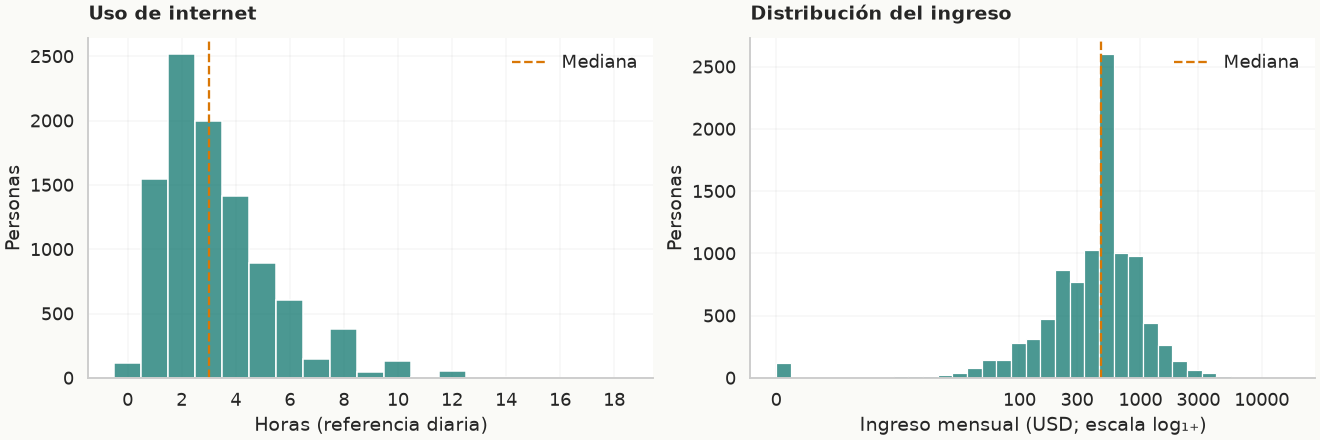

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=muestra, x='pt3b', discrete=True, color=verde, ax=axes[0])
axes[0].axvline(muestra['pt3b'].median(), color=naranja, linestyle='--', label='Mediana')
axes[0].set(title='Uso de internet', xlabel='Horas (referencia diaria)', ylabel='Personas', xticks=range(0, 19, 2))
axes[0].legend(frameon=False)

sns.histplot(x=np.log1p(muestra['ingrl'].to_numpy(dtype=float)), bins=35, color=verde, ax=axes[1])
marcas = np.array([0, 100, 300, 1000, 3000, 10000])
axes[1].set(title='Distribución del ingreso', xlabel='Ingreso mensual (USD; escala log₁₊)',
            ylabel='Personas', xticks=np.log1p(marcas), xticklabels=marcas)
axes[1].axvline(np.log1p(muestra['ingrl'].median()), color=naranja, linestyle='--', label='Mediana')
axes[1].legend(frameon=False)
plt.show()

La mediana es **3 horas** y **USD 474**. El ingreso presenta una cola derecha larga; la escala log₁₊ facilita verla sin quitar los ceros.

## Asociación
Cada punto es una persona. Los dos paneles mantienen todas las observaciones; el segundo transforma solo la visualización del ingreso.

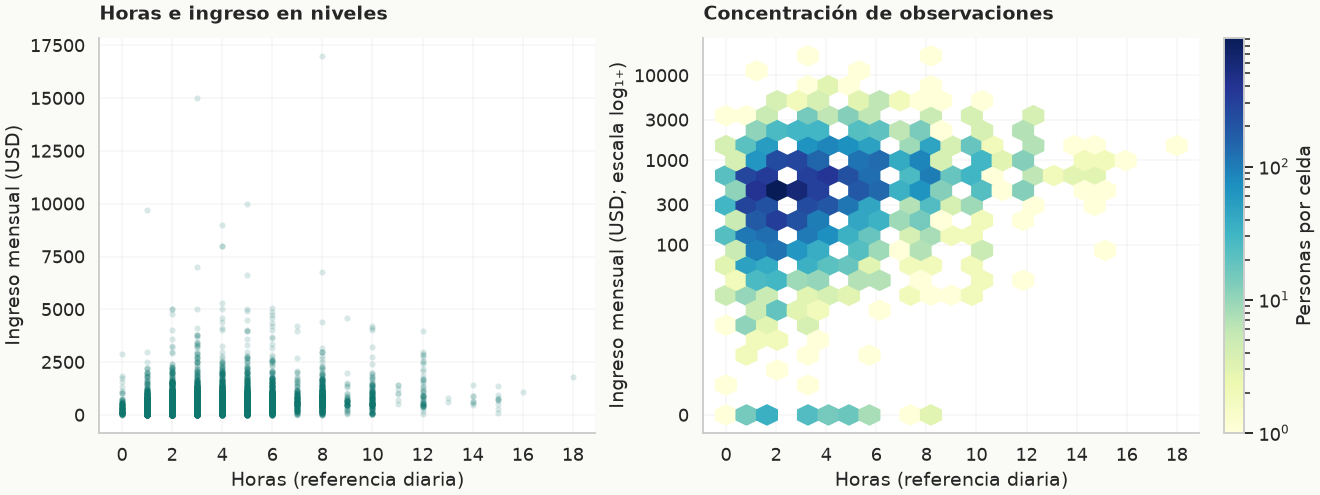

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=muestra, x='pt3b', y='ingrl', s=16, alpha=0.16,
                linewidth=0, color=verde, ax=axes[0])
axes[0].set(title='Horas e ingreso en niveles', xlabel='Horas (referencia diaria)',
            ylabel='Ingreso mensual (USD)', xticks=range(0, 19, 2))

densidad = axes[1].hexbin(muestra['pt3b'].to_numpy(dtype=float),
                          np.log1p(muestra['ingrl'].to_numpy(dtype=float)),
                          gridsize=22, mincnt=1, bins='log', cmap='YlGnBu')
axes[1].set(title='Concentración de observaciones', xlabel='Horas (referencia diaria)',
            ylabel='Ingreso mensual (USD; escala log₁₊)', xticks=range(0, 19, 2),
            yticks=np.log1p(marcas), yticklabels=marcas)
fig.colorbar(densidad, ax=axes[1], label='Personas por celda')
plt.show()

### Por tramos
Los tramos solo resumen la relación; no reemplazan las horas continuas en el futuro modelo.

,Personas,Media,Mediana
tramo,,,
0–1,1661,404.58,350.0
2–3,4515,515.65,470.0
4–5,2312,639.16,500.0
6–8,1132,810.55,656.0
9 o más,261,913.98,710.0


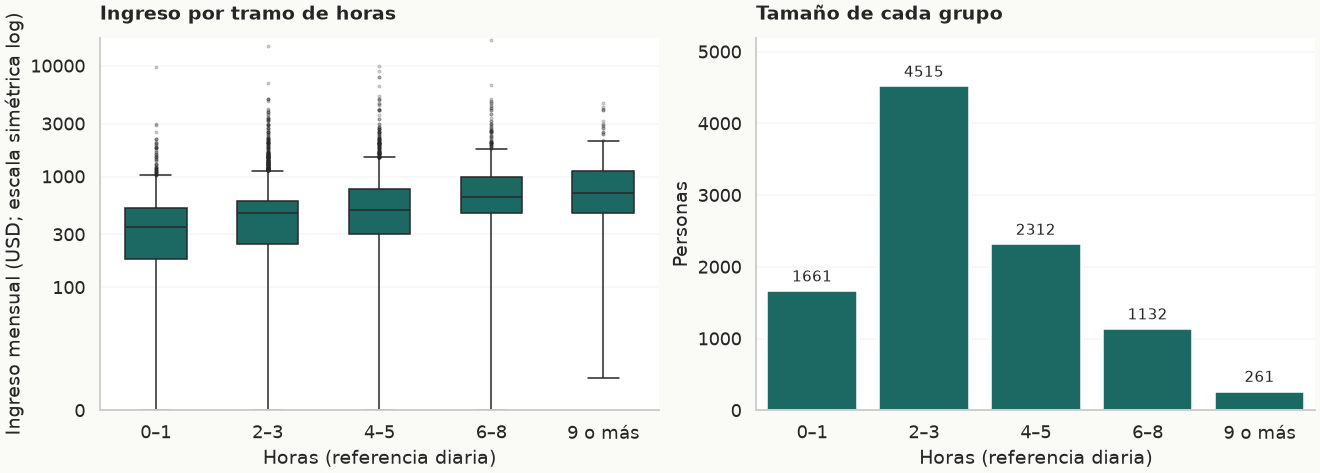

In [8]:
muestra['tramo'] = pd.cut(muestra['pt3b'], bins=[-1, 1, 3, 5, 8, np.inf],
                          labels=['0–1', '2–3', '4–5', '6–8', '9 o más'])
por_tramo = muestra.groupby('tramo', observed=True)['ingrl'].agg(
    Personas='size', Media='mean', Mediana='median'
)
display(por_tramo.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.boxplot(data=muestra, x='tramo', y='ingrl', color=verde, width=0.55,
            flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.3}, ax=axes[0])
axes[0].set_yscale('symlog', linthresh=100)
axes[0].set_ylim(bottom=0)
axes[0].set(title='Ingreso por tramo de horas', xlabel='Horas (referencia diaria)',
            ylabel='Ingreso mensual (USD; escala simétrica log)',
            yticks=marcas, yticklabels=marcas)

sns.countplot(data=muestra, x='tramo', color=verde, ax=axes[1])
axes[1].set(title='Tamaño de cada grupo', xlabel='Horas (referencia diaria)', ylabel='Personas')
axes[1].bar_label(axes[1].containers[0], padding=4, fontsize=10)
axes[1].margins(y=0.15)
plt.show()

La mediana aumenta entre tramos, con amplia dispersión dentro de cada grupo. Esto sugiere asociación, pero las horas por sí solas no resumen toda la variación del ingreso.

## Pesos y correlaciones
`fexp` se usa como peso descriptivo. Los gráficos anteriores no están ponderados. No se calculan pruebas ni intervalos: la inferencia posterior debe considerar `estrato` y `upm`.

In [9]:
x = muestra['pt3b'].to_numpy(dtype=float)
y = muestra['ingrl'].to_numpy(dtype=float)
w = muestra['fexp'].to_numpy(dtype=float)
assert np.isfinite(w).all() and (w > 0).all(), 'Revisar los pesos de la muestra'

medias = pd.DataFrame({
    'Media simple': [x.mean(), y.mean()],
    'Media ponderada': [np.average(x, weights=w), np.average(y, weights=w)]
}, index=['Horas de internet', 'Ingreso laboral (USD)'])

xc, yc = x - np.average(x, weights=w), y - np.average(y, weights=w)
r_ponderada = np.sum(w * xc * yc) / np.sqrt(np.sum(w * xc**2) * np.sum(w * yc**2))
correlaciones = pd.Series({
    'Pearson': muestra[['pt3b', 'ingrl']].corr().iloc[0, 1],
    'Spearman': muestra[['pt3b', 'ingrl']].rank().corr().iloc[0, 1],
    'Pearson ponderado': r_ponderada
}, name='Correlación')
display(medias.round(2), correlaciones.round(3).to_frame())

,Media simple,Media ponderada
Horas de internet,3.36,3.07
Ingreso laboral (USD),570.19,506.25


,Correlación
Pearson,0.228
Spearman,0.270
Pearson ponderado,0.232


Las tres medidas son positivas y de magnitud baja. La ponderación cambia los niveles medios, pero mantiene el sentido de la asociación en este dominio.

## Sensibilidad
Se compara la asociación con y sin la cola superior y con ingresos positivos. Son escenarios exploratorios: **no se eliminan filas de la base limpia**.

In [10]:
p99 = muestra['ingrl'].quantile(.99)
escenarios = {
    'Muestra completa': muestra,
    'Ingreso hasta P99': muestra.loc[muestra['ingrl'].le(p99)],
    'Ingreso positivo': muestra.loc[muestra['ingrl'].gt(0)]
}
sensibilidad = pd.DataFrame({
    nombre: {'Personas': len(grupo),
             'Pearson': grupo[['pt3b', 'ingrl']].corr().iloc[0, 1],
             'Spearman': grupo[['pt3b', 'ingrl']].rank().corr().iloc[0, 1]}
    for nombre, grupo in escenarios.items()
}).T
sensibilidad['Personas'] = sensibilidad['Personas'].astype(int)
display(sensibilidad.round(3))
print(f'Percentil 99 del ingreso: USD {p99:,.0f}.')

,Personas,Pearson,Spearman
Muestra completa,9881,0.228,0.270
Ingreso hasta P99,9783,0.269,0.263
Ingreso positivo,9762,0.229,0.277


Percentil 99 del ingreso: USD 2,680.


## Conclusiones
- En **9.881 ocupados con uso diario y ambas respuestas**, la asociación es positiva y débil: Pearson **0,228** y Spearman **0,270**.
- Con `fexp`, Pearson es **0,232**. El sentido positivo se mantiene en los escenarios de sensibilidad.
- La dispersión y la cola del ingreso justifican revisar linealidad, heterocedasticidad y observaciones influyentes en el modelo simple.

**Alcance:** describe este grupo, no a todos los ocupados de Ecuador. Los pesos no corrigen automáticamente la selección por respuestas disponibles. La asociación no prueba causalidad ni independencia de observaciones del mismo hogar o UPM.